IMPORTS

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold

LOAD DATASET

In [3]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

PREPARING THE DATASET

In [4]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)


In [7]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

QUESTION 1

In [8]:
for n in numerical:
    score = roc_auc_score(y_train, df_train[n].values)
    if score < 0.5:
        negate = -df_train[n].values
        score = roc_auc_score(y_train, negate)
    print(n, score)

annual_income 0.6081977776250831
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
lead_score 0.7882254810906102


QUESTION 2

In [9]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model


def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred


dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
auc_score = roc_auc_score(y_val, y_pred)
round(auc_score, 3)

0.732

QUESTION 3

In [10]:
def precision_recall(y_true, y_score):
    scores = []
    thresholds = np.linspace(0, 1, 101)

    actual_positive = (y_true == 1)
    actual_negative = (y_true == 0)

    for t in thresholds:
        predicted_positive = (y_score >= t)
        predicted_negative = (y_score < t)

        tp = (actual_positive & predicted_positive).sum()
        tn = (actual_negative & predicted_negative).sum()

        fp = (actual_negative & predicted_positive).sum()
        fn = (actual_positive & predicted_negative).sum()

        scores.append((t, tp, tn, fp, fn))

    columns = ['threshold', 'tp', 'tn', 'fp', 'fn']
    df_scores = pd.DataFrame(scores, columns=columns)
        
    df_scores['precision'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fp'])
    df_scores['recall'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fn'])
    df_scores['abs_precision_recall_diff'] = (df_scores['precision'] - df_scores['recall']).abs()
    df_scores['F1_score'] = 2 * (df_scores['precision'] * df_scores['recall']) / (df_scores['precision'] + df_scores['recall'])
    
    return df_scores


df_scores = precision_recall(y_val, y_pred)

In [11]:
df_scores

,threshold,tp,tn,fp,fn,precision,recall,abs_precision_recall_diff,F1_score
0,0.00,586,0,414,0,0.586,1.000000,0.414000,0.738966
1,0.01,586,0,414,0,0.586,1.000000,0.414000,0.738966
2,0.02,586,0,414,0,0.586,1.000000,0.414000,0.738966
3,0.03,586,0,414,0,0.586,1.000000,0.414000,0.738966
4,0.04,586,0,414,0,0.586,1.000000,0.414000,0.738966
...,...,...,...,...,...,...,...,...,...
96,0.96,1,414,0,585,1.000,0.001706,0.998294,0.003407
97,0.97,0,414,0,586,NaN,0.000000,NaN,NaN
98,0.98,0,414,0,586,NaN,0.000000,NaN,NaN
99,0.99,0,414,0,586,NaN,0.000000,NaN,NaN


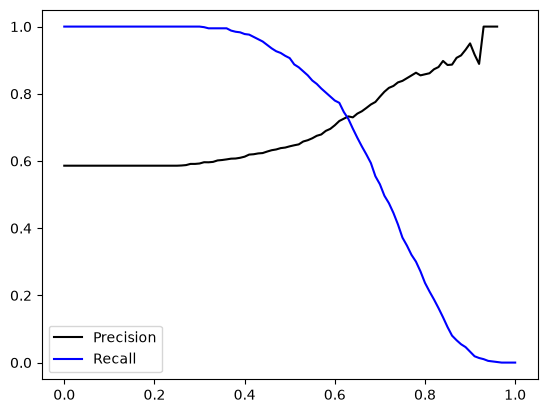

In [14]:
plt.plot(df_scores.threshold, df_scores['precision'], label='Precision', color='black')
plt.plot(df_scores.threshold, df_scores['recall'], label='Recall', color='blue')
plt.legend()

In [15]:
both_zero = (df_scores['precision'] == 0) & (df_scores['recall'] == 0)

filtered = df_scores[~both_zero]
best_idx = filtered['abs_precision_recall_diff'].idxmin()

df_scores.loc[best_idx, ['threshold', 'precision', 'recall', 'abs_precision_recall_diff']]

threshold                    0.630000
precision                    0.732759
recall                       0.725256
abs_precision_recall_diff    0.007503
Name: 63, dtype: float64

QUESTION 4

In [16]:
max_f1 = df_scores['F1_score'].idxmax()
df_scores.loc[max_f1, ['threshold', 'F1_score']]

threshold    0.410000
F1_score     0.757616
Name: 41, dtype: float64

QUESTION 5

In [17]:
def cross_validate(C=1.0, n_splits=5):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc_score = roc_auc_score(y_val, y_pred)
        scores.append(auc_score)

    return scores

In [18]:
fold_scores = cross_validate(1.0)
fold_scores_std = round(np.std(fold_scores), 3)
fold_scores_std

np.float64(0.007)

QUESTION 6

In [26]:
C_values = [0.000001, 0.001, 1]

for c in C_values:
    fold_scores = cross_validate(c)
    print(f'C: {c}    Mean: {round(np.mean(fold_scores), 3)}          Standard Deviation: {round(np.std(fold_scores), 3)}')

C: 1e-06    Mean: 0.617          Standard Deviation: 0.019
C: 0.001    Mean: 0.749          Standard Deviation: 0.01
C: 1    Mean: 0.732          Standard Deviation: 0.007
